In [2]:
# STEP 1: AUDIT EXISTING FORECASTING DATASETS

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: LOCATE PROJECT DATA
# ------------------------------------------------------------

project_root = Path.cwd()
processed_dir = project_root / "data" / "processed"

weekly_path = processed_dir / "airpods_weekly_2019.csv"

predictions_path = (
    processed_dir / "model_predictions_rolling_2019.csv"
)

performance_path = (
    processed_dir / "model_performance_rolling_2019.csv"
)

for path in [
    weekly_path,
    predictions_path,
    performance_path
]:
    assert path.is_file(), f"Missing file: {path.name}"

print("===== FORECASTING FILES LOCATED =====")

print("All three historical forecasting files found.")


# ------------------------------------------------------------
# PART 2: LOAD HISTORICAL DEMAND
# ------------------------------------------------------------

weekly_df = pd.read_csv(weekly_path)

weekly_df["Week_Ending"] = pd.to_datetime(
    weekly_df["Week_Ending"],
    errors="raise"
)

weekly_df = (
    weekly_df
    .sort_values("Week_Ending")
    .reset_index(drop=True)
)

print("\n===== HISTORICAL WEEKLY DEMAND =====")

print("Observations:", len(weekly_df))

print(
    "Start date:",
    weekly_df["Week_Ending"].min().date()
)

print(
    "End date:",
    weekly_df["Week_Ending"].max().date()
)

print(
    "Total units:",
    weekly_df["Units_Sold"].sum()
)

print(
    "Average weekly units:",
    round(weekly_df["Units_Sold"].mean(), 2)
)

print(
    "Standard deviation:",
    round(weekly_df["Units_Sold"].std(), 2)
)

display(weekly_df.head())


# ------------------------------------------------------------
# PART 3: VALIDATE HISTORICAL DATA QUALITY
# ------------------------------------------------------------

missing_values = weekly_df.isna().sum().sum()

duplicate_weeks = weekly_df[
    "Week_Ending"
].duplicated().sum()

invalid_demand = (
    weekly_df["Units_Sold"] < 0
).sum()

week_gaps = (
    weekly_df["Week_Ending"]
    .diff()
    .dropna()
    .dt.days
)

irregular_intervals = (week_gaps != 7).sum()

print("\n===== HISTORICAL DATA VALIDATION =====")

print("Missing values:", missing_values)

print("Duplicate weeks:", duplicate_weeks)

print("Negative demand values:", invalid_demand)

print("Irregular weekly intervals:", irregular_intervals)

assert missing_values == 0
assert duplicate_weeks == 0
assert invalid_demand == 0

print("Historical demand checks: PASS")


# ------------------------------------------------------------
# PART 4: LOAD PREVIOUS ROLLING FORECASTS
# ------------------------------------------------------------

predictions_df = pd.read_csv(predictions_path)

predictions_df["Week_Ending"] = pd.to_datetime(
    predictions_df["Week_Ending"],
    errors="raise"
)

predictions_df = (
    predictions_df
    .sort_values("Week_Ending")
    .reset_index(drop=True)
)

print("\n===== EXISTING ROLLING FORECASTS =====")

print("Backtest observations:", len(predictions_df))

print("\nForecast columns:")

print(predictions_df.columns.tolist())

display(predictions_df.head())


# ------------------------------------------------------------
# PART 5: VERIFY FORECAST ACTUALS
# ------------------------------------------------------------

actual_check = predictions_df[
    ["Week_Ending", "Actual_Units"]
].merge(
    weekly_df[["Week_Ending", "Units_Sold"]],
    on="Week_Ending",
    how="left",
    validate="one_to_one",
    indicator=True
)

unmatched_weeks = (
    actual_check["_merge"] != "both"
).sum()

actual_mismatches = (
    actual_check["Actual_Units"]
    != actual_check["Units_Sold"]
).sum()

print("\n===== FORECAST DATA RECONCILIATION =====")

print("Unmatched forecast weeks:", unmatched_weeks)

print("Actual unit mismatches:", actual_mismatches)

assert unmatched_weeks == 0
assert actual_mismatches == 0

print("Forecast actuals reconciled: PASS")


# ------------------------------------------------------------
# PART 6: REVIEW PREVIOUS MODEL PERFORMANCE
# ------------------------------------------------------------

performance_df = pd.read_csv(performance_path)

print("\n===== PREVIOUS FORECAST MODEL LEADERBOARD =====")

display(
    performance_df.sort_values(
        "WAPE (%)",
        ascending=True
    )
)

print("\n===== STEP 1 COMPLETE =====")


===== FORECASTING FILES LOCATED =====
All three historical forecasting files found.

===== HISTORICAL WEEKLY DEMAND =====
Observations: 51
Start date: 2019-01-13
End date: 2019-12-29
Total units: 15364
Average weekly units: 301.25
Standard deviation: 76.46


,Week_Ending,Units_Sold
0,2019-01-13,187
1,2019-01-20,184
2,2019-01-27,175
3,2019-02-03,225
4,2019-02-10,247



===== HISTORICAL DATA VALIDATION =====
Missing values: 0
Duplicate weeks: 0
Negative demand values: 0
Irregular weekly intervals: 0
Historical demand checks: PASS

===== EXISTING ROLLING FORECASTS =====
Backtest observations: 19

Forecast columns:
['Week_Ending', 'Actual_Units', 'Naive_Forecast', 'MA4_Forecast', 'Holt_Forecast', 'Linear_Trend_Forecast', 'Ridge_Forecast']


,Week_Ending,Actual_Units,Naive_Forecast,MA4_Forecast,Holt_Forecast,Linear_Trend_Forecast,Ridge_Forecast
0,2019-06-02,263,312,316.50,343.711872,374.457895,322.155958
1,2019-06-09,267,263,302.75,331.210438,361.814286,304.918822
2,2019-06-16,275,267,298.25,270.868345,351.714286,303.440797
3,2019-06-23,265,275,279.25,262.932684,344.387352,294.371375
4,2019-06-30,283,265,267.50,255.182520,336.336957,287.282947



===== FORECAST DATA RECONCILIATION =====
Unmatched forecast weeks: 0
Actual unit mismatches: 0
Forecast actuals reconciled: PASS

===== PREVIOUS FORECAST MODEL LEADERBOARD =====


,Rank,Model,MAE,WAPE (%),Bias,Forecast_Horizon_Weeks,Number_of_Forecasts
0,1,Naive Forecast,22.157895,8.600613,-3.421053,1,19
1,2,4-Week Moving Average,26.565789,10.311542,4.460526,1,19
2,3,Holt's Damped Trend,28.241258,10.961877,1.095026,1,19
3,4,Ridge Regression,32.679159,12.684454,18.201122,1,19
4,5,Linear Regression,66.412483,25.778083,54.063901,1,19



===== STEP 1 COMPLETE =====


In [3]:
# STEP 2: MULTI-HORIZON ROLLING-ORIGIN VALIDATION DESIGN

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: DEFINE FORECAST HORIZONS
# ------------------------------------------------------------

forecast_horizons = [1, 2, 4]

# Require at least 32 observed weeks before forecasting
minimum_training_weeks = 32

maximum_horizon = max(forecast_horizons)

print("===== FORECAST VALIDATION CONFIGURATION =====")

print("Forecast horizons:", forecast_horizons)
print("Minimum training weeks:", minimum_training_weeks)
print("Historical observations:", len(weekly_df))


# ------------------------------------------------------------
# PART 2: DEFINE COMMON EVALUATION PERIOD
# ------------------------------------------------------------

# All horizons will predict the SAME target weeks.
# This makes the horizon comparison more consistent.

first_target_index = (
    minimum_training_weeks + maximum_horizon - 1
)

target_indices = range(
    first_target_index,
    len(weekly_df)
)

print("\n===== COMMON EVALUATION PERIOD =====")

print("Evaluation target weeks:", len(target_indices))

print(
    "First target:",
    weekly_df.iloc[first_target_index]["Week_Ending"].date()
)

print(
    "Last target:",
    weekly_df.iloc[-1]["Week_Ending"].date()
)


# ------------------------------------------------------------
# PART 3: BUILD ROLLING-ORIGIN EVALUATION SCHEDULE
# ------------------------------------------------------------

validation_records = []

for target_idx in target_indices:

    target_row = weekly_df.iloc[target_idx]

    for horizon in forecast_horizons:

        # Forecast originates 'horizon' weeks earlier.
        origin_idx = target_idx - horizon

        # Only historical observations available at origin.
        training_history = weekly_df.iloc[:origin_idx + 1]

        origin_row = weekly_df.iloc[origin_idx]

        validation_records.append({

            "Target_Index": target_idx,

            "Origin_Index": origin_idx,

            "Horizon_Weeks": horizon,

            "Origin_Week": origin_row["Week_Ending"],

            "Target_Week": target_row["Week_Ending"],

            "Training_Weeks": len(training_history),

            "Actual_Units": target_row["Units_Sold"]

        })


# ------------------------------------------------------------
# PART 4: CREATE VALIDATION SCHEDULE
# ------------------------------------------------------------

rolling_schedule = pd.DataFrame(
    validation_records
)

rolling_schedule = (
    rolling_schedule
    .sort_values(
        ["Target_Week", "Horizon_Weeks"]
    )
    .reset_index(drop=True)
)

print("\n===== ROLLING-ORIGIN VALIDATION SCHEDULE =====")

display(rolling_schedule.head(12))


# ------------------------------------------------------------
# PART 5: SUMMARIZE EACH FORECAST HORIZON
# ------------------------------------------------------------

horizon_summary = (
    rolling_schedule
    .groupby("Horizon_Weeks")
    .agg(
        Forecasts=("Actual_Units", "size"),
        Minimum_Training_Weeks=("Training_Weeks", "min"),
        Maximum_Training_Weeks=("Training_Weeks", "max"),
        First_Target=("Target_Week", "min"),
        Last_Target=("Target_Week", "max")
    )
    .reset_index()
)

print("\n===== HORIZON VALIDATION SUMMARY =====")

display(horizon_summary)


# ------------------------------------------------------------
# PART 6: CHECK FOR DATA LEAKAGE
# ------------------------------------------------------------

# Every forecast must originate before the target date.
assert (
    rolling_schedule["Origin_Week"]
    < rolling_schedule["Target_Week"]
).all()

# Date separation must match the forecast horizon.
actual_gap_days = (
    rolling_schedule["Target_Week"]
    - rolling_schedule["Origin_Week"]
).dt.days

expected_gap_days = (
    rolling_schedule["Horizon_Weeks"] * 7
)

assert (
    actual_gap_days == expected_gap_days
).all()

# Every origin must have sufficient training history.
assert (
    rolling_schedule["Training_Weeks"]
    >= minimum_training_weeks
).all()

# Each forecast horizon must predict the same target weeks.
target_sets = [
    set(
        rolling_schedule.loc[
            rolling_schedule["Horizon_Weeks"] == h,
            "Target_Week"
        ]
    )
    for h in forecast_horizons
]

assert all(
    targets == target_sets[0]
    for targets in target_sets
)

# Expected: 16 target weeks x 3 horizons = 48 forecasts.
assert len(rolling_schedule) == 48

print("\n===== DATA LEAKAGE VALIDATION =====")

print("Forecast origins precede target dates: PASS")
print("Forecast horizon date separation: PASS")
print("Minimum historical training length: PASS")
print("Common target weeks across horizons: PASS")

print("\nTotal evaluation cases:", len(rolling_schedule))

print("\n===== STEP 2 COMPLETE =====")


===== FORECAST VALIDATION CONFIGURATION =====
Forecast horizons: [1, 2, 4]
Minimum training weeks: 32
Historical observations: 51

===== COMMON EVALUATION PERIOD =====
Evaluation target weeks: 16
First target: 2019-09-15
Last target: 2019-12-29

===== ROLLING-ORIGIN VALIDATION SCHEDULE =====


,Target_Index,Origin_Index,Horizon_Weeks,Origin_Week,Target_Week,Training_Weeks,Actual_Units
0,35,34,1,2019-09-08,2019-09-15,35,235
1,35,33,2,2019-09-01,2019-09-15,34,235
2,35,31,4,2019-08-18,2019-09-15,32,235
3,36,35,1,2019-09-15,2019-09-22,36,210
4,36,34,2,2019-09-08,2019-09-22,35,210
5,36,32,4,2019-08-25,2019-09-22,33,210
6,37,36,1,2019-09-22,2019-09-29,37,229
7,37,35,2,2019-09-15,2019-09-29,36,229
8,37,33,4,2019-09-01,2019-09-29,34,229
9,38,37,1,2019-09-29,2019-10-06,38,377



===== HORIZON VALIDATION SUMMARY =====


,Horizon_Weeks,Forecasts,Minimum_Training_Weeks,Maximum_Training_Weeks,First_Target,Last_Target
0,1,16,35,50,2019-09-15,2019-12-29
1,2,16,34,49,2019-09-15,2019-12-29
2,4,16,32,47,2019-09-15,2019-12-29



===== DATA LEAKAGE VALIDATION =====
Forecast origins precede target dates: PASS
Forecast horizon date separation: PASS
Minimum historical training length: PASS
Common target weeks across horizons: PASS

Total evaluation cases: 48

===== STEP 2 COMPLETE =====


In [4]:
# STEP 3: GENERATE MULTI-HORIZON DEMAND FORECASTS

import numpy as np
import pandas as pd

from sklearn.linear_model import (
    LinearRegression,
    Ridge
)

from statsmodels.tsa.holtwinters import Holt

# ------------------------------------------------------------
# PART 1: DEFINE FORECASTING FUNCTION
# ------------------------------------------------------------

def generate_forecasts(history, horizon):

    history = np.asarray(
        history,
        dtype=float
    )

    n = len(history)

    assert n >= 4
    assert horizon >= 1

    # MODEL 1: NAIVE FORECAST
    naive_forecast = history[-1]

    # MODEL 2: FOUR-WEEK MOVING AVERAGE
    ma4_forecast = history[-4:].mean()

    # MODEL 3: HOLT'S DAMPED TREND
    holt_model = Holt(
        history,
        damped_trend=True,
        initialization_method="estimated"
    ).fit(optimized=True)

    holt_forecast = float(
        np.asarray(
            holt_model.forecast(horizon)
        )[-1]
    )

    # MODEL 4: LINEAR REGRESSION
    X_train = np.arange(n).reshape(-1, 1)
    y_train = history

    future_index = np.array([
        [n - 1 + horizon]
    ])

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    linear_forecast = float(
        linear_model.predict(future_index)[0]
    )

    # MODEL 5: RIDGE REGRESSION
    ridge_model = Ridge(alpha=100.0)
    ridge_model.fit(X_train, y_train)

    ridge_forecast = float(
        ridge_model.predict(future_index)[0]
    )

    # Forecasts represent physical unit demand.
    # Prevent negative forecast quantities.
    return {
        "Naive Forecast": max(
            0.0, naive_forecast
        ),
        "4-Week Moving Average": max(
            0.0, ma4_forecast
        ),
        "Holt's Damped Trend": max(
            0.0, holt_forecast
        ),
        "Linear Regression": max(
            0.0, linear_forecast
        ),
        "Ridge Regression": max(
            0.0, ridge_forecast
        )
    }


# ------------------------------------------------------------
# PART 2: RUN ROLLING-ORIGIN FORECASTS
# ------------------------------------------------------------

forecast_records = []

for row in rolling_schedule.itertuples(index=False):

    # Use only observations available at forecast origin.
    training_history = (
        weekly_df.iloc[
            :row.Origin_Index + 1
        ]["Units_Sold"]
        .to_numpy(dtype=float)
    )

    horizon = int(row.Horizon_Weeks)

    assert len(training_history) == row.Training_Weeks

    forecasts = generate_forecasts(
        training_history,
        horizon
    )

    # Store one prediction per model.
    for model_name, predicted_units in forecasts.items():

        actual_units = float(row.Actual_Units)

        forecast_records.append({
            "Origin_Week": row.Origin_Week,
            "Target_Week": row.Target_Week,
            "Horizon_Weeks": horizon,
            "Training_Weeks": row.Training_Weeks,
            "Model": model_name,
            "Actual_Units": actual_units,
            "Forecast_Units": predicted_units,
            "Error": predicted_units - actual_units,
            "Absolute_Error": abs(
                predicted_units - actual_units
            )
        })


# ------------------------------------------------------------
# PART 3: BUILD FORECAST RESULTS TABLE
# ------------------------------------------------------------

multihorizon_predictions = pd.DataFrame(
    forecast_records
)

multihorizon_predictions = (
    multihorizon_predictions
    .sort_values([
        "Horizon_Weeks",
        "Target_Week",
        "Model"
    ])
    .reset_index(drop=True)
)

print("===== MULTI-HORIZON FORECASTS =====")

print(
    "Total predictions:",
    len(multihorizon_predictions)
)

display(
    multihorizon_predictions.head(10).round(2)
)


# ------------------------------------------------------------
# PART 4: CALCULATE MODEL PERFORMANCE
# ------------------------------------------------------------

multihorizon_performance = (
    multihorizon_predictions
    .groupby(
        ["Horizon_Weeks", "Model"]
    )
    .agg(
        Forecasts=("Actual_Units", "size"),
        Total_Actual_Units=("Actual_Units", "sum"),
        Total_Absolute_Error=("Absolute_Error", "sum"),
        MAE=("Absolute_Error", "mean"),
        Bias=("Error", "mean")
    )
    .reset_index()
)

# WAPE = sum of absolute errors / sum of actual demand
multihorizon_performance["WAPE_Pct"] = (
    multihorizon_performance["Total_Absolute_Error"]
    /
    multihorizon_performance["Total_Actual_Units"]
    * 100
)

# Rank models separately within each forecast horizon.
multihorizon_performance = (
    multihorizon_performance
    .sort_values(
        ["Horizon_Weeks", "WAPE_Pct"]
    )
    .reset_index(drop=True)
)

multihorizon_performance["Rank"] = (
    multihorizon_performance
    .groupby("Horizon_Weeks")
    .cumcount() + 1
)


# ------------------------------------------------------------
# PART 5: DISPLAY MODEL LEADERBOARD
# ------------------------------------------------------------

print("\n===== MULTI-HORIZON MODEL LEADERBOARD =====")

display(
    multihorizon_performance[
        [
            "Horizon_Weeks",
            "Rank",
            "Model",
            "Forecasts",
            "MAE",
            "WAPE_Pct",
            "Bias"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 6: IDENTIFY BEST MODEL PER HORIZON
# ------------------------------------------------------------

best_models = (
    multihorizon_performance[
        multihorizon_performance["Rank"] == 1
    ]
    .copy()
)

print("\n===== BEST MODEL BY FORECAST HORIZON =====")

display(
    best_models[
        [
            "Horizon_Weeks",
            "Model",
            "MAE",
            "WAPE_Pct",
            "Bias"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 7: VALIDATE FORECASTING EXPERIMENT
# ------------------------------------------------------------

assert len(multihorizon_predictions) == 240

assert len(multihorizon_performance) == 15

assert (
    multihorizon_performance["Forecasts"] == 16
).all()

assert (
    multihorizon_predictions["Origin_Week"]
    < multihorizon_predictions["Target_Week"]
).all()

assert (
    multihorizon_predictions["Forecast_Units"] >= 0
).all()

assert np.isfinite(
    multihorizon_predictions["Forecast_Units"]
).all()

print("\n===== FORECAST VALIDATION =====")

print("240 historical predictions: PASS")
print("15 model/horizon combinations: PASS")
print("16 forecasts per combination: PASS")
print("Forecast origins precede targets: PASS")
print("Nonnegative finite forecasts: PASS")

print("\n===== STEP 3 COMPLETE =====")


===== MULTI-HORIZON FORECASTS =====
Total predictions: 240


/var/folders/9c/495l1cs96zj_67bnbpkg5lm80000gn/T/ipykernel_24833/309059705.py:163: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  multihorizon_predictions.head(10).round(2)


,Origin_Week,Target_Week,Horizon_Weeks,Training_Weeks,Model,Actual_Units,Forecast_Units,Error,Absolute_Error
0,2019-09-08,2019-09-15,1,35,4-Week Moving Average,235.0,233.00,-2.00,2.00
1,2019-09-08,2019-09-15,1,35,Holt's Damped Trend,235.0,228.00,-7.00,7.00
2,2019-09-08,2019-09-15,1,35,Linear Regression,235.0,274.48,39.48,39.48
3,2019-09-08,2019-09-15,1,35,Naive Forecast,235.0,231.00,-4.00,4.00
4,2019-09-08,2019-09-15,1,35,Ridge Regression,235.0,274.42,39.42,39.42
5,2019-09-15,2019-09-22,1,36,4-Week Moving Average,210.0,233.00,23.00,23.00
6,2019-09-15,2019-09-22,1,36,Holt's Damped Trend,210.0,229.66,19.66,19.66
7,2019-09-15,2019-09-22,1,36,Linear Regression,210.0,270.21,60.21,60.21
8,2019-09-15,2019-09-22,1,36,Naive Forecast,210.0,235.00,25.00,25.00
9,2019-09-15,2019-09-22,1,36,Ridge Regression,210.0,270.24,60.24,60.24



===== MULTI-HORIZON MODEL LEADERBOARD =====


,Horizon_Weeks,Rank,Model,Forecasts,MAE,WAPE_Pct,Bias
0,1,1,Naive Forecast,16,31.50,8.64,-17.75
1,1,2,Holt's Damped Trend,16,36.59,10.03,-25.99
2,1,3,4-Week Moving Average,16,49.17,13.49,-39.20
3,1,4,Linear Regression,16,79.33,21.76,-62.54
4,1,5,Ridge Regression,16,79.60,21.83,-62.80
5,2,1,Naive Forecast,16,43.88,12.03,-31.25
6,2,2,Holt's Damped Trend,16,49.72,13.63,-40.51
7,2,3,4-Week Moving Average,16,64.30,17.63,-51.98
8,2,4,Linear Regression,16,85.67,23.50,-66.82
9,2,5,Ridge Regression,16,85.89,23.55,-67.06



===== BEST MODEL BY FORECAST HORIZON =====


,Horizon_Weeks,Model,MAE,WAPE_Pct,Bias
0,1,Naive Forecast,31.50,8.64,-17.75
5,2,Naive Forecast,43.88,12.03,-31.25
10,4,Naive Forecast,75.12,20.60,-60.62



===== FORECAST VALIDATION =====
240 historical predictions: PASS
15 model/horizon combinations: PASS
16 forecasts per combination: PASS
Forecast origins precede targets: PASS
Nonnegative finite forecasts: PASS

===== STEP 3 COMPLETE =====


===== NAIVE FORECAST DATA =====
Forecast records: 48

===== FORECAST UNCERTAINTY SUMMARY =====


,Horizon_Weeks,Forecasts,MAE,RMSE,Bias,Underforecast_Weeks,Overforecast_Weeks,P80_Absolute_Error,P90_Absolute_Error,P90_Underforecast_Units,Maximum_Absolute_Error
0,1,16,31.50,49.26,-17.75,10,6,38.0,76.5,76.5,148.0
1,2,16,43.88,69.87,-31.25,10,6,105.0,133.0,133.0,167.0
2,4,16,75.12,97.44,-60.62,9,6,143.0,150.0,150.0,159.0



===== FORECAST STABILITY ANALYSIS =====


,Horizon_Weeks,Period,Forecasts,MAE,WAPE_Pct,Bias
0,1,First 8 Weeks,8,28.00,8.83,-18.50
1,1,Last 8 Weeks,8,35.00,8.49,-17.00
2,2,First 8 Weeks,8,46.25,14.59,-35.00
3,2,Last 8 Weeks,8,41.50,10.07,-27.50
4,4,First 8 Weeks,8,75.88,23.94,-69.12
5,4,Last 8 Weeks,8,74.38,18.04,-52.12


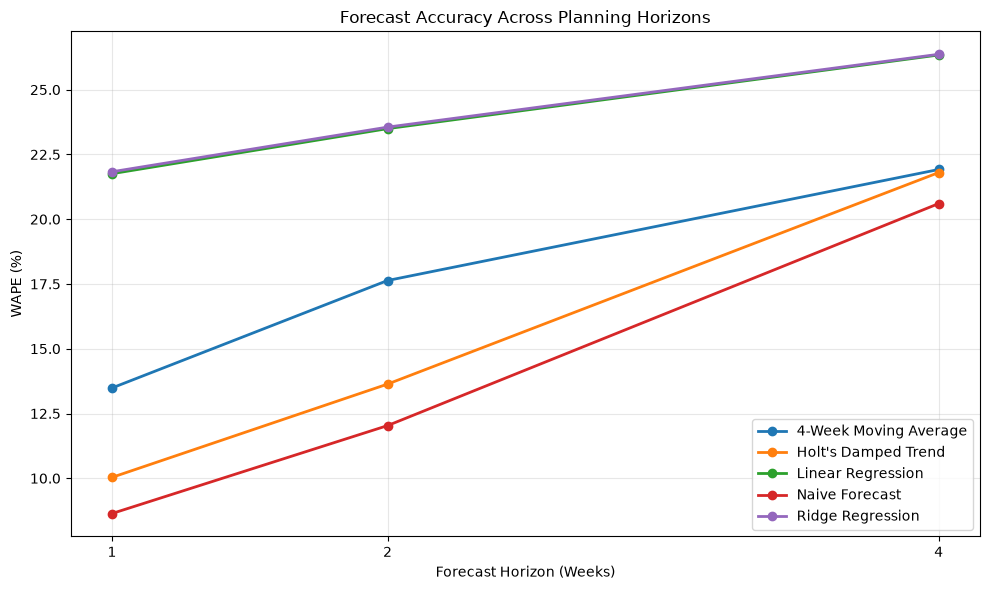

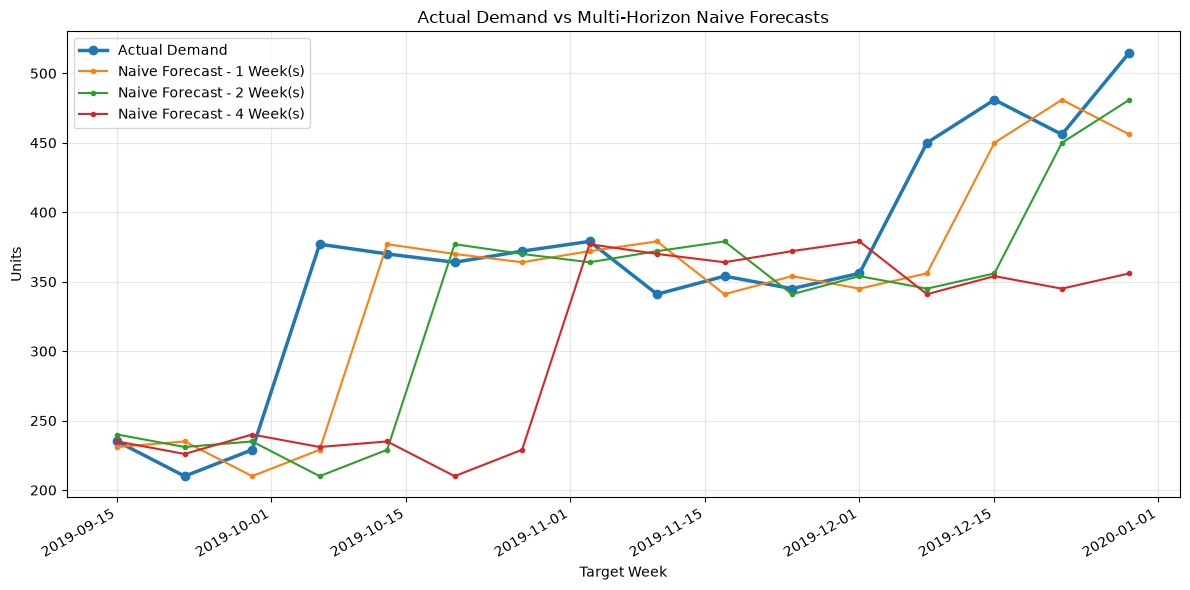


===== UNCERTAINTY VALIDATION =====
Three forecasting horizons: PASS
Six temporal stability comparisons: PASS
Historical error percentiles: PASS
Underforecast/overforecast counts: PASS

===== STEP 4 COMPLETE =====


In [5]:
# STEP 4: ANALYZE FORECAST ERRORS AND UNCERTAINTY

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PART 1: ISOLATE NAIVE MODEL FORECASTS
# ------------------------------------------------------------

naive_results = (
    multihorizon_predictions[
        multihorizon_predictions["Model"] == "Naive Forecast"
    ]
    .copy()
    .sort_values(["Horizon_Weeks", "Target_Week"])
    .reset_index(drop=True)
)

# Positive values represent demand above forecast.
naive_results["Underforecast_Units"] = (
    naive_results["Actual_Units"]
    - naive_results["Forecast_Units"]
).clip(lower=0)

# Positive values represent forecast above demand.
naive_results["Overforecast_Units"] = (
    naive_results["Forecast_Units"]
    - naive_results["Actual_Units"]
).clip(lower=0)

print("===== NAIVE FORECAST DATA =====")
print("Forecast records:", len(naive_results))

assert len(naive_results) == 48


# ------------------------------------------------------------
# PART 2: QUANTIFY HISTORICAL FORECAST UNCERTAINTY
# ------------------------------------------------------------

uncertainty_records = []

for horizon, group in naive_results.groupby("Horizon_Weeks"):

    errors = group["Error"].to_numpy(dtype=float)
    absolute_errors = np.abs(errors)

    underforecast = group[
        "Underforecast_Units"
    ].to_numpy(dtype=float)

    uncertainty_records.append({
        "Horizon_Weeks": horizon,

        "Forecasts": len(group),

        "MAE": absolute_errors.mean(),

        "RMSE": np.sqrt(
            np.mean(errors ** 2)
        ),

        "Bias": errors.mean(),

        "Underforecast_Weeks": int(
            (errors < 0).sum()
        ),

        "Overforecast_Weeks": int(
            (errors > 0).sum()
        ),

        "P80_Absolute_Error": np.percentile(
            absolute_errors, 80
        ),

        "P90_Absolute_Error": np.percentile(
            absolute_errors, 90
        ),

        "P90_Underforecast_Units": np.percentile(
            underforecast, 90
        ),

        "Maximum_Absolute_Error": absolute_errors.max()
    })


uncertainty_summary = pd.DataFrame(
    uncertainty_records
).sort_values("Horizon_Weeks")

print("\n===== FORECAST UNCERTAINTY SUMMARY =====")

display(uncertainty_summary.round(2))


# ------------------------------------------------------------
# PART 3: COMPARE EARLY VERSUS LATE EVALUATION PERIODS
# ------------------------------------------------------------

stability_records = []

for horizon, group in naive_results.groupby("Horizon_Weeks"):

    group = group.sort_values("Target_Week")

    midpoint = len(group) // 2

    periods = {
        "First 8 Weeks": group.iloc[:midpoint],
        "Last 8 Weeks": group.iloc[midpoint:]
    }

    for period_name, period_df in periods.items():

        actual_sum = period_df["Actual_Units"].sum()

        wape = (
            period_df["Absolute_Error"].sum()
            / actual_sum * 100
        )

        stability_records.append({
            "Horizon_Weeks": horizon,
            "Period": period_name,
            "Forecasts": len(period_df),
            "MAE": period_df["Absolute_Error"].mean(),
            "WAPE_Pct": wape,
            "Bias": period_df["Error"].mean()
        })


stability_summary = pd.DataFrame(
    stability_records
)

print("\n===== FORECAST STABILITY ANALYSIS =====")

display(stability_summary.round(2))


# ------------------------------------------------------------
# PART 4: VISUALIZE WAPE ACROSS FORECAST HORIZONS
# ------------------------------------------------------------

wape_comparison = (
    multihorizon_performance
    .pivot(
        index="Horizon_Weeks",
        columns="Model",
        values="WAPE_Pct"
    )
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 6))

for model_name in wape_comparison.columns:

    ax.plot(
        wape_comparison.index,
        wape_comparison[model_name],
        marker="o",
        linewidth=2,
        label=model_name
    )

ax.set_title(
    "Forecast Accuracy Across Planning Horizons"
)

ax.set_xlabel("Forecast Horizon (Weeks)")
ax.set_ylabel("WAPE (%)")

ax.set_xticks([1, 2, 4])
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# PART 5: VISUALIZE ACTUAL VS NAIVE FORECAST DEMAND
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

actual_data = (
    naive_results[
        naive_results["Horizon_Weeks"] == 1
    ]
    .sort_values("Target_Week")
)

ax.plot(
    actual_data["Target_Week"],
    actual_data["Actual_Units"],
    marker="o",
    linewidth=2.5,
    label="Actual Demand"
)

for horizon in [1, 2, 4]:

    horizon_df = naive_results[
        naive_results["Horizon_Weeks"] == horizon
    ].sort_values("Target_Week")

    ax.plot(
        horizon_df["Target_Week"],
        horizon_df["Forecast_Units"],
        marker=".",
        linewidth=1.5,
        label=f"Naive Forecast - {horizon} Week(s)"
    )

ax.set_title(
    "Actual Demand vs Multi-Horizon Naive Forecasts"
)

ax.set_xlabel("Target Week")
ax.set_ylabel("Units")

ax.grid(alpha=0.3)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# PART 6: VALIDATE UNCERTAINTY RESULTS
# ------------------------------------------------------------

assert len(uncertainty_summary) == 3
assert len(stability_summary) == 6

assert (
    uncertainty_summary["Forecasts"] == 16
).all()

assert (
    uncertainty_summary["P90_Absolute_Error"]
    >= uncertainty_summary["P80_Absolute_Error"]
).all()

assert (
    uncertainty_summary["Underforecast_Weeks"]
    + uncertainty_summary["Overforecast_Weeks"]
    <= uncertainty_summary["Forecasts"]
).all()

print("\n===== UNCERTAINTY VALIDATION =====")

print("Three forecasting horizons: PASS")
print("Six temporal stability comparisons: PASS")
print("Historical error percentiles: PASS")
print("Underforecast/overforecast counts: PASS")

print("\n===== STEP 4 COMPLETE =====")


In [6]:
# STEP 5: EXPORT FORECASTING RESULTS FOR INVENTORY PLANNING

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: DEFINE EXPORT LOCATION
# ------------------------------------------------------------

forecast_output_dir = project_root / "data" / "processed"

forecast_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("===== FORECASTING EXPORT LOCATION =====")
print(forecast_output_dir)


# ------------------------------------------------------------
# PART 2: BUILD HISTORICAL LEAD-TIME DEMAND BASELINE
# ------------------------------------------------------------

# Use the final observation as the historical forecast origin.
# This creates an illustrative forecast for early 2020,
# NOT a current or live market forecast.

last_observed_week = weekly_df["Week_Ending"].max()

last_observed_units = float(
    weekly_df.loc[
        weekly_df["Week_Ending"] == last_observed_week,
        "Units_Sold"
    ].iloc[0]
)

print("\n===== HISTORICAL FORECAST ORIGIN =====")

print(
    "Last observed week:",
    last_observed_week.date()
)

print(
    "Last observed weekly demand:",
    last_observed_units
)


# ------------------------------------------------------------
# PART 3: GENERATE FOUR-WEEK FORWARD BASELINE
# ------------------------------------------------------------

# The naive model assumes each future week has demand
# equal to the latest observed week.

lead_time_records = []

cumulative_demand = 0.0

for horizon in range(1, 5):

    forecast_week = (
        last_observed_week
        + pd.Timedelta(weeks=horizon)
    )

    forecast_units = last_observed_units

    cumulative_demand += forecast_units

    lead_time_records.append({
        "Forecast_Origin": last_observed_week,
        "Forecast_Week": forecast_week,
        "Lead_Time_Weeks": horizon,
        "Model": "Naive Forecast",
        "Forecast_Weekly_Units": forecast_units,
        "Cumulative_Forecast_Units": cumulative_demand,
        "Scenario_Type": "Historical Illustrative Baseline"
    })


lead_time_baseline = pd.DataFrame(
    lead_time_records
)

print("\n===== LEAD-TIME DEMAND BASELINE =====")

display(lead_time_baseline)


# ------------------------------------------------------------
# PART 4: VALIDATE PLANNING BASELINE
# ------------------------------------------------------------

assert len(lead_time_baseline) == 4

assert (
    lead_time_baseline["Forecast_Weekly_Units"] >= 0
).all()

assert (
    lead_time_baseline["Cumulative_Forecast_Units"]
    .is_monotonic_increasing
)

assert np.isclose(
    lead_time_baseline[
        "Cumulative_Forecast_Units"
    ].iloc[-1],
    last_observed_units * 4
)

print("\n===== LEAD-TIME VALIDATION =====")

print("Four future weeks generated: PASS")
print("Nonnegative forecast quantities: PASS")
print("Cumulative demand reconciliation: PASS")


# ------------------------------------------------------------
# PART 5: DEFINE FORECASTING OUTPUT FILES
# ------------------------------------------------------------

forecast_exports = {
    "forecast_multihorizon_predictions_2019.csv":
        multihorizon_predictions,

    "forecast_multihorizon_performance_2019.csv":
        multihorizon_performance,

    "forecast_uncertainty_summary_2019.csv":
        uncertainty_summary,

    "forecast_stability_summary_2019.csv":
        stability_summary,

    "forecast_lead_time_baseline_2019.csv":
        lead_time_baseline
}


# ------------------------------------------------------------
# PART 6: EXPORT ALL FIVE FILES
# ------------------------------------------------------------

export_records = []

for filename, dataframe in forecast_exports.items():

    output_path = forecast_output_dir / filename

    dataframe.to_csv(
        output_path,
        index=False,
        date_format="%Y-%m-%d"
    )

    # Reload to confirm the file was written correctly.
    verified = pd.read_csv(output_path)

    assert len(verified) == len(dataframe)

    assert (
        verified.columns.tolist()
        == dataframe.columns.tolist()
    )

    assert output_path.stat().st_size > 0

    export_records.append({
        "File": filename,
        "Rows": len(verified),
        "Columns": len(verified.columns),
        "Status": "PASS"
    })

    print(
        f"Exported: {filename} "
        f"({len(verified)} rows)"
    )


# ------------------------------------------------------------
# PART 7: VALIDATE ALL FORECASTING OUTPUTS
# ------------------------------------------------------------

forecast_export_report = pd.DataFrame(
    export_records
)

expected_rows = {
    "forecast_multihorizon_predictions_2019.csv": 240,
    "forecast_multihorizon_performance_2019.csv": 15,
    "forecast_uncertainty_summary_2019.csv": 3,
    "forecast_stability_summary_2019.csv": 6,
    "forecast_lead_time_baseline_2019.csv": 4
}

for record in export_records:

    assert record["Rows"] == expected_rows[
        record["File"]
    ]

print("\n===== FORECAST EXPORT VALIDATION =====")

display(forecast_export_report)

assert len(forecast_export_report) == 5

assert (
    forecast_export_report["Status"] == "PASS"
).all()

print("\n===== STEP 5 COMPLETE =====")


===== FORECASTING EXPORT LOCATION =====
/Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/processed

===== HISTORICAL FORECAST ORIGIN =====
Last observed week: 2019-12-29
Last observed weekly demand: 515.0

===== LEAD-TIME DEMAND BASELINE =====


,Forecast_Origin,Forecast_Week,Lead_Time_Weeks,Model,Forecast_Weekly_Units,Cumulative_Forecast_Units,Scenario_Type
0,2019-12-29,2020-01-05,1,Naive Forecast,515.0,515.0,Historical Illustrative Baseline
1,2019-12-29,2020-01-12,2,Naive Forecast,515.0,1030.0,Historical Illustrative Baseline
2,2019-12-29,2020-01-19,3,Naive Forecast,515.0,1545.0,Historical Illustrative Baseline
3,2019-12-29,2020-01-26,4,Naive Forecast,515.0,2060.0,Historical Illustrative Baseline



===== LEAD-TIME VALIDATION =====
Four future weeks generated: PASS
Nonnegative forecast quantities: PASS
Cumulative demand reconciliation: PASS
Exported: forecast_multihorizon_predictions_2019.csv (240 rows)
Exported: forecast_multihorizon_performance_2019.csv (15 rows)
Exported: forecast_uncertainty_summary_2019.csv (3 rows)
Exported: forecast_stability_summary_2019.csv (6 rows)
Exported: forecast_lead_time_baseline_2019.csv (4 rows)

===== FORECAST EXPORT VALIDATION =====


,File,Rows,Columns,Status
0,forecast_multihorizon_predictions_2019.csv,240,9,PASS
1,forecast_multihorizon_performance_2019.csv,15,9,PASS
2,forecast_uncertainty_summary_2019.csv,3,11,PASS
3,forecast_stability_summary_2019.csv,6,6,PASS
4,forecast_lead_time_baseline_2019.csv,4,7,PASS



===== STEP 5 COMPLETE =====


In [7]:
# STEP 6A: INTEGRATE FORECASTING OUTPUTS INTO DUCKDB

import duckdb
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# PART 1: CONNECT TO THE EXISTING DATABASE
# ------------------------------------------------------------

database_path = (
    project_root
    / "data"
    / "warehouse"
    / "demand_intelligence.duckdb"
)

assert database_path.is_file(), "Database not found."

forecast_con = duckdb.connect(str(database_path))

print("===== FORECASTING DATABASE CONNECTION =====")
print("Connected successfully.")

try:

    # --------------------------------------------------------
    # PART 2: DEFINE NEW FORECASTING TABLES
    # --------------------------------------------------------

    new_forecast_tables = {
        "forecast_multihorizon_predictions_2019.csv": {
            "Rows": 240,
            "Grain": "Origin x Target x Horizon x Model",
            "Meaning": "Historical rolling-origin predictions",
            "Role": "Forecast validation",
            "Date_Column": "Target_Week"
        },

        "forecast_multihorizon_performance_2019.csv": {
            "Rows": 15,
            "Grain": "Horizon x Model",
            "Meaning": "Multi-horizon forecasting accuracy",
            "Role": "Model evaluation",
            "Date_Column": None
        },

        "forecast_uncertainty_summary_2019.csv": {
            "Rows": 3,
            "Grain": "Forecast Horizon",
            "Meaning": "Historical naive forecast error statistics",
            "Role": "Forecast risk",
            "Date_Column": None
        },

        "forecast_stability_summary_2019.csv": {
            "Rows": 6,
            "Grain": "Horizon x Evaluation Period",
            "Meaning": "Early versus late forecasting performance",
            "Role": "Model stability",
            "Date_Column": None
        },

        "forecast_lead_time_baseline_2019.csv": {
            "Rows": 4,
            "Grain": "Illustrative Forecast Week",
            "Meaning": "Weekly and cumulative lead-time demand",
            "Role": "Inventory scenario input",
            "Date_Column": "Forecast_Week"
        }
    }

    load_records = []

    # --------------------------------------------------------
    # PART 3: LOAD FIVE NEW FORECAST TABLES
    # --------------------------------------------------------

    for filename, spec in new_forecast_tables.items():

        file_path = processed_dir / filename

        assert file_path.is_file(), (
            f"Missing file: {filename}"
        )

        df = pd.read_csv(file_path)

        assert len(df) == spec["Rows"]

        table_name = Path(filename).stem

        assert table_name.isidentifier()

        forecast_con.register(
            "incoming_forecast",
            df
        )

        try:

            forecast_con.execute(
                f"""
                CREATE OR REPLACE TABLE
                    demand.{table_name}
                AS
                SELECT *
                FROM incoming_forecast
                """
            ).fetchall()

        finally:

            forecast_con.unregister("incoming_forecast")

        sql_count = forecast_con.execute(
            f"""
            SELECT COUNT(*)
            FROM demand.{table_name}
            """
        ).fetchall()[0][0]

        assert sql_count == len(df)

        # ----------------------------------------------------
        # PART 4: UPDATE ARCHITECTURE METADATA
        # ----------------------------------------------------

        forecast_con.execute(
            """
            DELETE FROM metadata.architecture_catalog
            WHERE File_Name = ?
            """,
            [filename]
        ).fetchall()

        forecast_con.execute(
            """
            INSERT INTO metadata.architecture_catalog
            (
                File_Name,
                Source_Module,
                Grain,
                Business_Meaning,
                Analytical_Role
            )
            VALUES (?, ?, ?, ?, ?)
            """,
            [
                filename,
                "Historical Demand Forecasting",
                spec["Grain"],
                spec["Meaning"],
                spec["Role"]
            ]
        ).fetchall()

        # ----------------------------------------------------
        # PART 5: UPDATE DATA QUALITY METADATA
        # ----------------------------------------------------

        missing_cells = int(
            df.isna().sum().sum()
        )

        duplicate_rows = int(
            df.duplicated().sum()
        )

        date_column = spec["Date_Column"]

        if date_column is not None:

            dates = pd.to_datetime(
                df[date_column],
                errors="raise"
            )

            start_date = str(dates.min().date())
            end_date = str(dates.max().date())

        else:

            start_date = "N/A"
            end_date = "N/A"

        forecast_con.execute(
            """
            DELETE FROM metadata.data_quality_report
            WHERE File_Name = ?
            """,
            [filename]
        ).fetchall()

        forecast_con.execute(
            """
            INSERT INTO metadata.data_quality_report
            (
                File_Name,
                Source_Module,
                Rows,
                Columns,
                Missing_Cells,
                Duplicate_Rows,
                Start_Date,
                End_Date,
                Row_Check
            )
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
            """,
            [
                filename,
                "Historical Demand Forecasting",
                len(df),
                len(df.columns),
                missing_cells,
                duplicate_rows,
                start_date,
                end_date,
                "PASS"
            ]
        ).fetchall()

        load_records.append({
            "Table": f"demand.{table_name}",
            "CSV_Rows": len(df),
            "SQL_Rows": sql_count,
            "Status": "PASS"
        })

        print(
            f"Loaded: demand.{table_name} "
            f"({sql_count} rows)"
        )

    # --------------------------------------------------------
    # PART 6: CREATE NEW REPORTING VIEWS
    # --------------------------------------------------------

    forecast_con.execute(
        """
        CREATE OR REPLACE VIEW
            reporting.v_forecast_multihorizon_performance
        AS
        SELECT
            Horizon_Weeks,
            Model,
            Forecasts,
            MAE,
            WAPE_Pct,
            Bias,
            Rank

        FROM demand.forecast_multihorizon_performance_2019
        """
    ).fetchall()

    forecast_con.execute(
        """
        CREATE OR REPLACE VIEW
            reporting.v_forecast_lead_time_baseline
        AS
        SELECT
            TRY_CAST(Forecast_Origin AS DATE)
                AS Forecast_Origin,

            TRY_CAST(Forecast_Week AS DATE)
                AS Forecast_Week,

            Lead_Time_Weeks,
            Model,
            Forecast_Weekly_Units,
            Cumulative_Forecast_Units,
            Scenario_Type

        FROM demand.forecast_lead_time_baseline_2019
        """
    ).fetchall()

    print("\n===== NEW REPORTING VIEWS CREATED =====")

    print("v_forecast_multihorizon_performance")
    print("v_forecast_lead_time_baseline")

    # --------------------------------------------------------
    # PART 7: VALIDATE NEW FORECASTING TABLES
    # --------------------------------------------------------

    forecast_load_report = pd.DataFrame(
        load_records
    )

    print("\n===== FORECASTING DATABASE LOAD REPORT =====")

    display(forecast_load_report)

    assert len(forecast_load_report) == 5

    assert (
        forecast_load_report["Status"] == "PASS"
    ).all()

    # --------------------------------------------------------
    # PART 8: VALIDATE COMPLETE DATABASE STRUCTURE
    # --------------------------------------------------------

    table_counts = forecast_con.execute(
        """
        SELECT
            table_schema AS Schema,
            COUNT(*) AS Tables

        FROM information_schema.tables

        WHERE table_schema IN (
            'demand',
            'ecommerce',
            'retail',
            'intent',
            'metadata'
        )

        AND table_type = 'BASE TABLE'

        GROUP BY table_schema
        ORDER BY table_schema
        """
    ).fetchall()

    schema_counts = pd.DataFrame(
        table_counts,
        columns=["Schema", "Tables"]
    )

    print("\n===== UPDATED DATABASE STRUCTURE =====")

    display(schema_counts)

    assert schema_counts["Tables"].sum() == 24

    # Confirm new metadata is fully cataloged.
    metadata_counts = forecast_con.execute(
        """
        SELECT
            (SELECT COUNT(*)
             FROM metadata.architecture_catalog),

            (SELECT COUNT(*)
             FROM metadata.data_quality_report)
        """
    ).fetchall()[0]

    assert metadata_counts == (21, 21)

    # Confirm total reporting views.
    view_count = forecast_con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.views
        WHERE table_schema = 'reporting'
        """
    ).fetchall()[0][0]

    assert view_count == 7

    # Validate new view row counts.
    performance_rows = forecast_con.execute(
        """
        SELECT COUNT(*)
        FROM reporting.v_forecast_multihorizon_performance
        """
    ).fetchall()[0][0]

    baseline_rows = forecast_con.execute(
        """
        SELECT COUNT(*)
        FROM reporting.v_forecast_lead_time_baseline
        """
    ).fetchall()[0][0]

    assert performance_rows == 15
    assert baseline_rows == 4

    print("\n===== FINAL DATABASE VALIDATION =====")

    print("Total SQL tables: 24")
    print("Total reporting views: 7")
    print("Architecture catalog entries: 21")
    print("Data quality catalog entries: 21")
    print("Five new forecasting tables: PASS")
    print("Two new reporting views: PASS")

    print("\n===== STEP 6A COMPLETE =====")

finally:

    forecast_con.close()

    print("\nDatabase connection closed safely.")


===== FORECASTING DATABASE CONNECTION =====
Connected successfully.
Loaded: demand.forecast_multihorizon_predictions_2019 (240 rows)
Loaded: demand.forecast_multihorizon_performance_2019 (15 rows)
Loaded: demand.forecast_uncertainty_summary_2019 (3 rows)
Loaded: demand.forecast_stability_summary_2019 (6 rows)
Loaded: demand.forecast_lead_time_baseline_2019 (4 rows)

===== NEW REPORTING VIEWS CREATED =====
v_forecast_multihorizon_performance
v_forecast_lead_time_baseline

===== FORECASTING DATABASE LOAD REPORT =====


,Table,CSV_Rows,SQL_Rows,Status
0,demand.forecast_multihorizon_predictions_2019,240,240,PASS
1,demand.forecast_multihorizon_performance_2019,15,15,PASS
2,demand.forecast_uncertainty_summary_2019,3,3,PASS
3,demand.forecast_stability_summary_2019,6,6,PASS
4,demand.forecast_lead_time_baseline_2019,4,4,PASS



===== UPDATED DATABASE STRUCTURE =====


,Schema,Tables
0,demand,8
1,ecommerce,4
2,intent,2
3,metadata,3
4,retail,7



===== FINAL DATABASE VALIDATION =====
Total SQL tables: 24
Total reporting views: 7
Architecture catalog entries: 21
Data quality catalog entries: 21
Five new forecasting tables: PASS
Two new reporting views: PASS

===== STEP 6A COMPLETE =====

Database connection closed safely.



# Multi-Horizon Forecasting Validation — Final Findings

## 1. Research Objective

Evaluate historical AirPods demand forecasting accuracy
across multiple planning horizons.

Develop a leakage-safe forecasting framework that can
support hypothetical inventory and replenishment scenarios.

## 2. Historical Demand

Dataset: Electronics Monthly Sales 2019

- 51 weekly observations
- 15,364 units sold
- Average weekly demand: 301.25 units
- Standard deviation: 76.46 units
- Historical period: January–December 2019

All historical records passed missing-value, duplicate,
negative-demand, and weekly-continuity checks.

## 3. Forecasting Methodology

Implemented expanding-window rolling-origin validation.

Forecast horizons:
- 1 week ahead
- 2 weeks ahead
- 4 weeks ahead

Evaluation design:
- 16 common target weeks per horizon
- Minimum 32 training weeks
- 48 forecast-origin/target combinations
- 240 predictions across five forecasting models

Models evaluated:
1. Naive Forecast
2. Four-Week Moving Average
3. Holt's Damped Trend
4. Linear Regression
5. Ridge Regression

All forecasts used historical information available
at their respective forecast origins.

## 4. Forecasting Results

The Naive Forecast achieved the lowest WAPE at every
evaluated horizon.

| Horizon | Best Model | MAE | WAPE | Bias |
|---|---|---:|---:|---:|
| 1 week | Naive | 31.50 | 8.64% | -17.75 |
| 2 weeks | Naive | 43.88 | 12.03% | -31.25 |
| 4 weeks | Naive | 75.12 | 20.60% | -60.62 |

Forecast accuracy deteriorated with longer planning
horizons.

The Naive Forecast also exhibited negative average bias
across all three horizons, indicating historical
underforecasting over the evaluation period.

## 5. Forecast Uncertainty

Naive forecast RMSE:
- 1 week: 49.26 units
- 2 weeks: 69.87 units
- 4 weeks: 97.44 units

Historical 90th-percentile absolute errors:
- 1 week: 76.5 units
- 2 weeks: 133 units
- 4 weeks: 150 units

These statistics summarize a limited historical sample.
They are not validated prediction intervals or
recommended safety-stock quantities.

## 6. Forecast Stability

Compared the first eight and last eight evaluation
weeks for every forecast horizon.

Four-week WAPE:
- First eight weeks: 23.94%
- Last eight weeks: 18.04%

Performance changed across evaluation periods,
reinforcing the need for monitoring and further
validation.

## 7. Illustrative Lead-Time Demand Baseline

Created a historical four-week forward baseline
using the final observed week of December 29, 2019.

Last observed demand: 515 units

Illustrative cumulative forecast:
- Week 1: 515 units
- Week 2: 1,030 units
- Week 3: 1,545 units
- Week 4: 2,060 units

The baseline assumes constant weekly demand.

It does not represent observed 2020 sales or a
validated operational forecast.

## 8. DuckDB Integration

Exported five forecasting CSV files.

Integrated five tables into the existing demand schema.

Created two SQL reporting views:
- reporting.v_forecast_multihorizon_performance
- reporting.v_forecast_lead_time_baseline

Expanded database:
- 24 persistent tables
- 7 reporting views
- 21 architecture metadata entries
- 21 data-quality metadata entries

All newly loaded table row counts were validated.

## 9. Business Implications

The forecasting framework provides:
- Model-performance comparisons
- Multi-horizon demand estimates
- Historical forecast error measures
- Underforecast-risk indicators
- Illustrative lead-time demand inputs

These outputs can support the design of inventory
replenishment and launch-readiness simulations.

## 10. Limitations and Next Steps

Key limitations:
- One product and one historical year
- Only 16 target weeks per horizon
- Limited evaluation of seasonal behavior
- No actual inventory or supplier lead-time records
- Historical error distributions may not generalize
- The four-week horizon predicts a specific future
  week, while inventory planning requires cumulative
  demand over the relevant lead-time period

Next development phase:
- Define hypothetical supply chain parameters
- Model inventory position and replenishment
- Evaluate demand-surge scenarios
- Simulate supplier delivery delays
- Quantify shortage exposure and service outcomes
- Build launch-readiness reporting
